# Stock 7: prices in the wrong units, and two clues that only work together

Stock 7's test row looks completely normal. The traps are in the **training prices** and in **how the clues work together**.

### The plan

| Part | What we do |
|---|---|
| 1 | Load and check the data |
| 2 | Clean the prices |
| 3 | Look at the clues: are they related to each other, and how do they move the price? |
| 4 | Test 11 models (and see what happens without cleaning) |
| 5 | Pick the most reliable model and look inside it |
| 6 | Measure how sure we are |
| 7 | Make a quote and a trading plan |

### Words used in this notebook

| Word | Meaning |
|---|---|
| **Clue** (= feature) | One column of the data, `x1` to `x8`. |
| **Correlation** | How much two columns move together in a straight line: +1, −1 or 0 (unrelated). |
| **Team effect** (= interaction) | Two clues that only change the price **together**, not one at a time. |
| **CV RMSE** | How many pounds a model is wrong by on rows it hasn't seen. Big misses count extra. |
| **MAE** (typical error) | The average size of a miss, ignoring direction. Big misses don't count extra. |
| **Jump** | A rare, large, random move in the price that no clue can explain. |

---
# Part 1: Load and check the data

### Step 1.1: Load the tools

**What this cell does:** loads the libraries (same as stock 3, plus `HuberRegressor`, a straight-line model that pays less attention to very large misses).

In [1]:
import warnings
warnings.filterwarnings("ignore")          # hide harmless library warnings so the output stays readable

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from math import erfc

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, SplineTransformer, FunctionTransformer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, cross_val_score, cross_val_predict
from sklearn.linear_model import LinearRegression, Ridge, HuberRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

print("All tools loaded.")

All tools loaded.


### Step 1.2: Open the data files

**What this cell does:** reads the training and test files and makes a list of the clue columns.

In [2]:
DATA_DIR = Path("../datasets")     # the data folder is one level up from this notebook
if not DATA_DIR.exists():          # in case the notebook was started from the main folder instead
    DATA_DIR = Path("datasets")

train = pd.read_csv(DATA_DIR / "stock_7_train.csv")   # the examples we learn from
test = pd.read_csv(DATA_DIR / "stock_7_test.csv")     # the one row we must price

clues = [c for c in train.columns if c.startswith("x")]   # x1 ... x8

print("Training data:", train.shape[0], "rows")
print("Test data:    ", test.shape[0], "row")
print("Clues:        ", clues)
display(test)
train.head()

Training data: 30000 rows
Test data:     1 row
Clues:         ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8']


,id,uid,x1,x2,x3,x4,x5,x6,x7,x8
0,stock_7,f16c18cc98,-0.8389,1.1173,0.2946,-1.3617,0.7309,-0.9547,0.1821,1.4701


,uid,x1,x2,x3,x4,x5,x6,x7,x8,price
0,96a8b257df,-0.0998,1.7196,0.2856,1.3136,0.9944,2.3693,-1.4469,0.5147,61.76
1,ff884e9c11,-2.6124,-0.9161,-0.0703,1.0428,-0.9499,0.0003,0.2818,-0.9819,3262.74
2,454579a8d6,0.4691,-1.1985,-0.4223,0.1613,1.3457,0.0541,-0.6173,-0.1920,67.72
3,cfe6e82762,-1.6729,-0.4300,-0.6218,-2.9199,1.2694,1.6837,-0.7517,-1.1526,51.70
4,266b684ad4,-0.7792,-0.8405,0.4711,-0.0668,-0.0511,0.6679,-1.4716,0.7096,50.60


**How to read the output:** 30,000 rows and 8 clues. Nothing is missing in the test row.

### Step 1.3: Health check

**What this cell does:** counts empty cells and repeated rows, checks whether the test row is inside the training range, and summarises the price.

In [3]:
print("Empty cells in train:", train.isna().sum().sum(), "   in test:", test.isna().sum().sum())
print("Repeated rows in train:", train[clues].duplicated().sum())

test_row = test[clues].iloc[0]
inside = (test_row >= train[clues].min()) & (test_row <= train[clues].max())
print("Test row inside the training range on every clue:", bool(inside.all()))

train["price"].describe().round(2)

Empty cells in train: 0    in test: 0
Repeated rows in train: 0
Test row inside the training range on every clue: True


count    30000.00
mean       173.23
std        810.49
min          1.00
25%         52.28
50%         57.53
75%         63.02
max       9048.62
Name: price, dtype: float64

**How to read the output**

* The data is complete, with no repeats, and the test row is normal.
* **But look at the price.** The **median** (50%) is about **£57.53**, while the **average** is about **£173**, and the maximum is about **£9,049**. When the average is three times the median, a few huge values are dragging it up. The minimum is exactly **£1.00**, which also looks suspicious.

> **✅ Checkpoint.** The clues look clean. The prices don't.

---
# Part 2: Clean the prices

### Step 2.1: Look at the strange prices

**What this cell does:** sorts all prices and shows the biggest gaps between neighbouring prices, then counts the very large and very small ones.

In [4]:
sorted_prices = np.sort(train["price"].values)
gaps = np.diff(sorted_prices)
biggest = np.argsort(gaps)[-3:][::-1]                        # the 3 biggest jumps between neighbouring prices
for i in biggest:
    print(f"Gap between £{sorted_prices[i]:,.2f} and £{sorted_prices[i + 1]:,.2f}")

print(f"\nPrices above £1,000: {(train['price'] > 1000).sum()}")
print(f"Prices below £5:     {(train['price'] < 5).sum()}   values: {sorted(train.loc[train['price'] < 5, 'price'].round(2).tolist())}")

big = train.loc[train["price"] > 1000, "price"]
normal = train.loc[(train["price"] >= 5) & (train["price"] <= 1000), "price"]
print(f"\nNormal prices:              average £{normal.mean():.2f}, std £{normal.std():.2f}")
print(f"Prices above £1,000 ÷ 100:  average £{(big / 100).mean():.2f}, std £{(big / 100).std():.2f}")

Gap between £148.39 and £2,814.28
Gap between £7,952.88 and £9,048.62
Gap between £2,879.31 and £3,262.74

Prices above £1,000: 613
Prices below £5:     8   values: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 2.94, 3.58]

Normal prices:              average £57.42, std £8.00
Prices above £1,000 ÷ 100:  average £57.26, std £8.17


**How to read the output**

* There's a huge empty gap between about **£148** (the largest normal price) and about **£2,814** (the smallest big one). Nothing lives in between.
* **613 prices are above £1,000.** Divide them by 100 and they look **exactly like normal prices** (same average, same spread). These prices were recorded **in pence instead of pounds**.
* **8 prices are below £5**, and six of them are exactly £1.00. Step 2.3 checks whether these are real.

### Step 2.2: Fix the prices

**What this cell does:**
1. divides the 613 "pence" prices by 100 (any cut-off inside the empty gap works; we use £1,000)
2. removes the 8 tiny prices for now (Step 2.3 shows why)
3. keeps the cleaned training rows in `clean`

In [5]:
in_pence = train["price"] > 1000                         # recorded in pence by mistake
too_small = train["price"] < 5                           # suspicious tiny prices

train["price_fixed"] = np.where(in_pence, train["price"] / 100, train["price"])
clean = train[~too_small].copy()

print(f"Rows fixed (÷100): {in_pence.sum()}    Rows removed: {too_small.sum()}    Rows left: {len(clean):,}")
clean["price_fixed"].describe().round(2)

Rows fixed (÷100): 613    Rows removed: 8    Rows left: 29,992


count    29992.00
mean        57.41
std          8.00
min          6.28
25%         52.17
50%         57.32
75%         62.59
max        148.39
Name: price_fixed, dtype: float64

**How to read the output:** now the average (about £57) and the median (about £57) agree, and the largest price is about £148. The prices look healthy.

### Step 2.3: Were the tiny prices real?

Maybe some stocks really are worth about £1. **What this cell does:** trains a simple straight-line model on the clean rows and asks what it would expect for the 8 tiny-price rows.

In [6]:
quick_model = LinearRegression().fit(clean[clues], clean["price_fixed"])
tiny = train[too_small]
pd.DataFrame({"actual price (£)": tiny["price"].values,
              "model expects (£)": quick_model.predict(tiny[clues]).round(2)})

,actual price (£),model expects (£)
0,1.00,60.98
1,1.00,50.79
2,1.00,62.89
3,1.00,51.90
4,2.94,68.02
5,1.00,39.27
6,1.00,55.68
7,3.58,42.00


**How to read the output:** for these rows the model expects normal prices (about £39–68), not £1–£4. Nothing in their clues explains a price that low, so they're **data errors**, and removing them is right.

> **✅ Checkpoint.** 613 prices were in pence (fixed by ÷100), and 8 were junk (removed). **Any model trained on the raw prices will be badly wrong** (Part 4 shows how badly).

---
# Part 3: Look at the clues

### Step 3.1: Are the clues related to each other?

If two clues move together, a model can't tell which one really matters (like house size and number of rooms). We check this three ways:

1. **Correlation**: straight-line links
2. **Correlation of squared values**: curved links (for example, one clue being big whenever another is far from 0, in either direction)
3. **Can a flexible model predict a clue from the other 7?** This catches **any** kind of link. A score (R²) of 0 means "no better than guessing".

**What this cell does:** draws the correlation heatmap and prints the three checks.

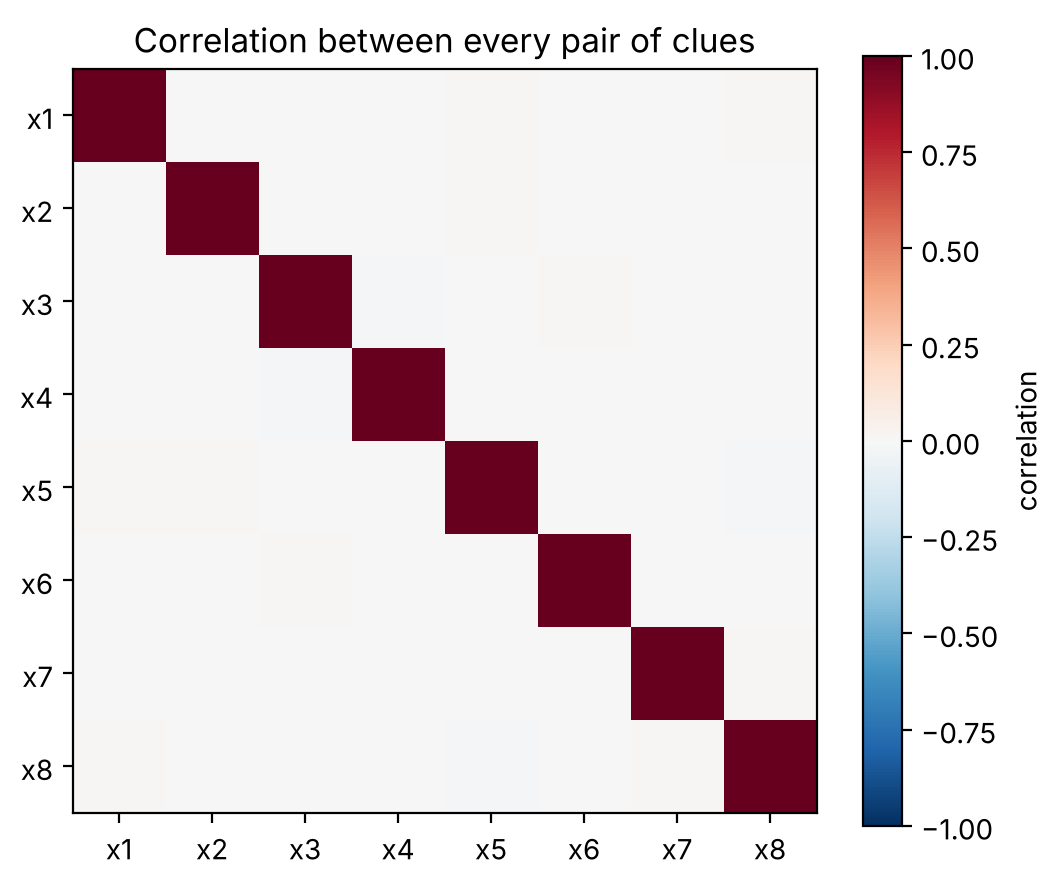

1. Largest straight-line correlation between two clues: 0.015
2. Largest correlation between squared clues:           0.019
3. How well each clue can be predicted from the other 7 (R², 0 = not at all):
   x1: -0.002


   x2: -0.002


   x3: -0.002


   x4: -0.002
   x5: -0.001


   x6: -0.004
   x7: -0.002


   x8: -0.003


In [7]:
corr = clean[clues].corr()

plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="correlation")
plt.xticks(range(8), clues); plt.yticks(range(8), clues)
plt.title("Correlation between every pair of clues")
plt.show()

off_diagonal = np.abs(corr.values[np.triu_indices(8, 1)])
squared_corr = np.abs((clean[clues] ** 2).corr().values[np.triu_indices(8, 1)])
print(f"1. Largest straight-line correlation between two clues: {off_diagonal.max():.3f}")
print(f"2. Largest correlation between squared clues:           {squared_corr.max():.3f}")

print("3. How well each clue can be predicted from the other 7 (R², 0 = not at all):")
for clue in clues:
    others = [c for c in clues if c != clue]
    r2 = cross_val_score(HistGradientBoostingRegressor(max_iter=100, random_state=0), clean[others], clean[clue],
                         cv=KFold(3, shuffle=True, random_state=0), scoring="r2").mean()
    print(f"   {clue}: {r2:+.3f}")

**How to read the output**

* The heatmap is white everywhere off the diagonal. The largest correlation is about **0.015**, which is basically 0.
* Squared clues aren't related either (about **0.02**).
* No clue can be predicted from the others (all R² ≈ 0).

**The clues are completely independent of each other.** That's good news: each clue's effect can be measured cleanly, with nothing to untangle.

### Step 3.2: How does each clue move the price?

**What this cell does:** cuts each clue into 10 slices (equal numbers of rows) and draws the average cleaned price in each slice. A flat line means no effect.

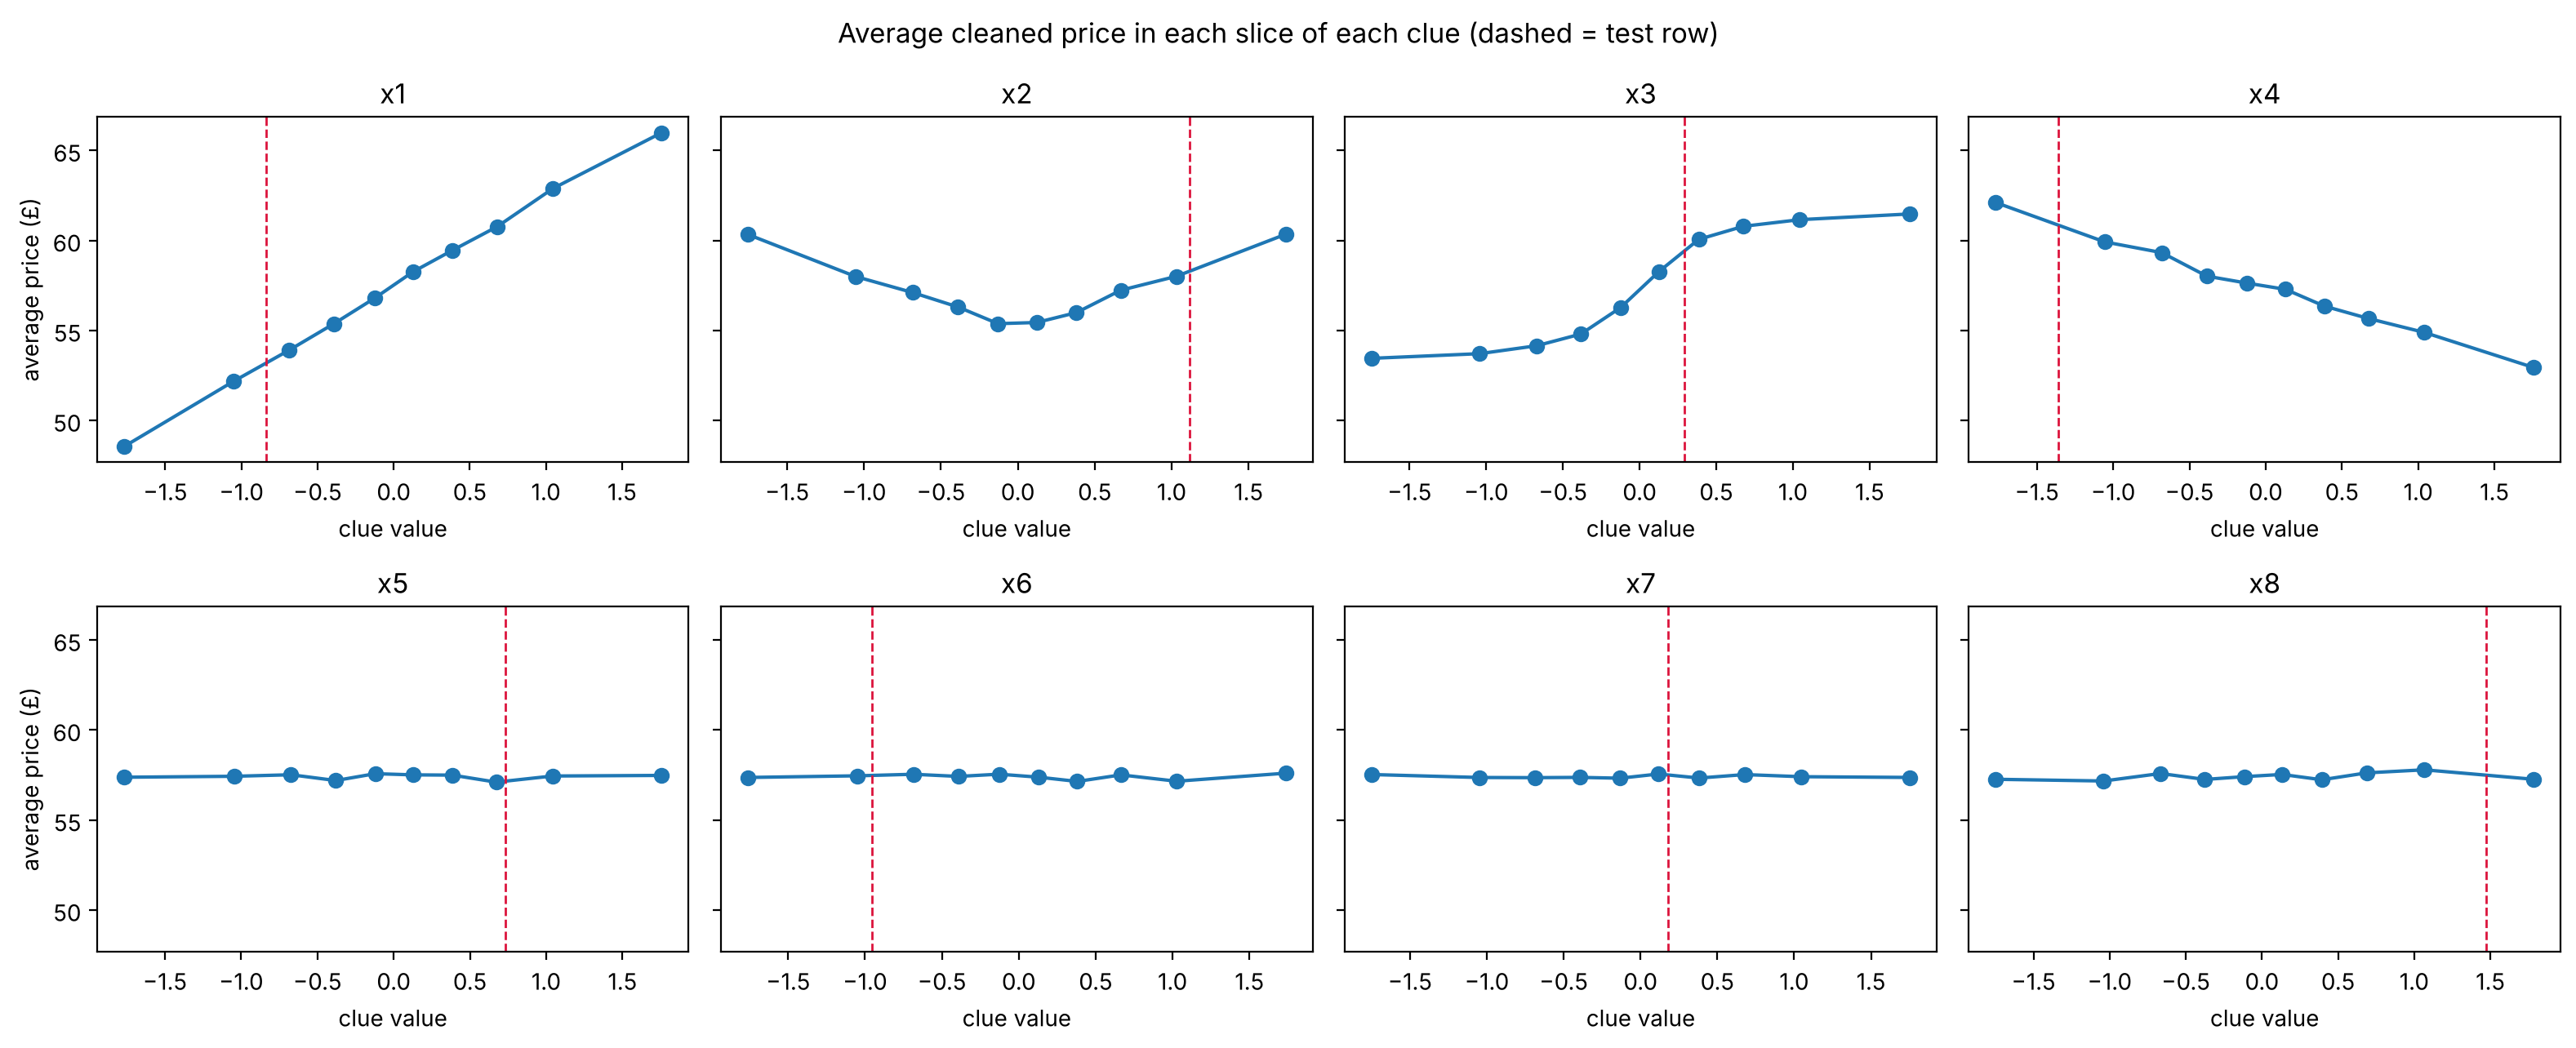

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharey=True)
for ax, clue in zip(axes.ravel(), clues):
    slices = pd.qcut(clean[clue], 10)                                  # 10 slices with equal numbers of rows
    clue_mid = clean[clue].groupby(slices, observed=True).mean()
    avg_price = clean["price_fixed"].groupby(slices, observed=True).mean()
    ax.plot(clue_mid.values, avg_price.values, marker="o")
    ax.axvline(test_row[clue], color="crimson", linestyle="--", linewidth=1)
    ax.set_title(clue); ax.set_xlabel("clue value")
axes[0, 0].set_ylabel("average price (£)"); axes[1, 0].set_ylabel("average price (£)")
fig.suptitle("Average cleaned price in each slice of each clue (dashed = test row)")
plt.tight_layout()
plt.show()

**How to read the output**

| Clue | Shape |
|---|---|
| x1 | Straight line **up** |
| x2 | **V-shape**: the price is higher when x2 is far from 0 on either side |
| x3 | **S-shape**: low on the left, high on the right, steep in the middle, flat at the ends |
| x4 | Straight line **down** |
| x5, x6, x7, x8 | **Flat**: no effect on their own |

### Step 3.3: Do any clues work as a team?

The clues are independent (Step 3.1), so if two clues only matter **together**, each one looks flat on its own. Think of a light that needs **two** switches: flipping one switch alone does nothing.

**What this cell does:**
1. fits a straight line using the shapes we can already see (x1, the V of x2, the S of x3, x4)
2. takes what's left of the price (the leftover)
3. checks every pair of clues: is "clue A × clue B" related to the leftover?

In [9]:
seen_so_far = pd.DataFrame({"x1": clean["x1"], "abs_x2": clean["x2"].abs(),
                            "s_x3": np.tanh(2 * clean["x3"]), "x4": clean["x4"]})
leftover = clean["price_fixed"] - LinearRegression().fit(seen_so_far, clean["price_fixed"]).predict(seen_so_far)

pairs = []
for i, a in enumerate(clues):
    for b in clues[i + 1:]:
        pairs.append({"pair": f"{a} × {b}", "correlation with leftover": np.corrcoef(clean[a] * clean[b], leftover)[0, 1]})
pd.DataFrame(pairs).sort_values("correlation with leftover", key=abs, ascending=False).head(6).round(3)

,pair,correlation with leftover
22,x5 × x6,0.341
9,x2 × x5,0.017
14,x3 × x5,0.012
4,x1 × x6,0.010
19,x4 × x6,-0.007
26,x6 × x8,0.006


**How to read the output:** one pair stands out by far. **x5 × x6** has a correlation of about **0.34** with the leftover, and every other pair is about 0.

**What this cell does:** shows the team effect as a picture: the average leftover for 5 slices of x5 against 5 slices of x6.

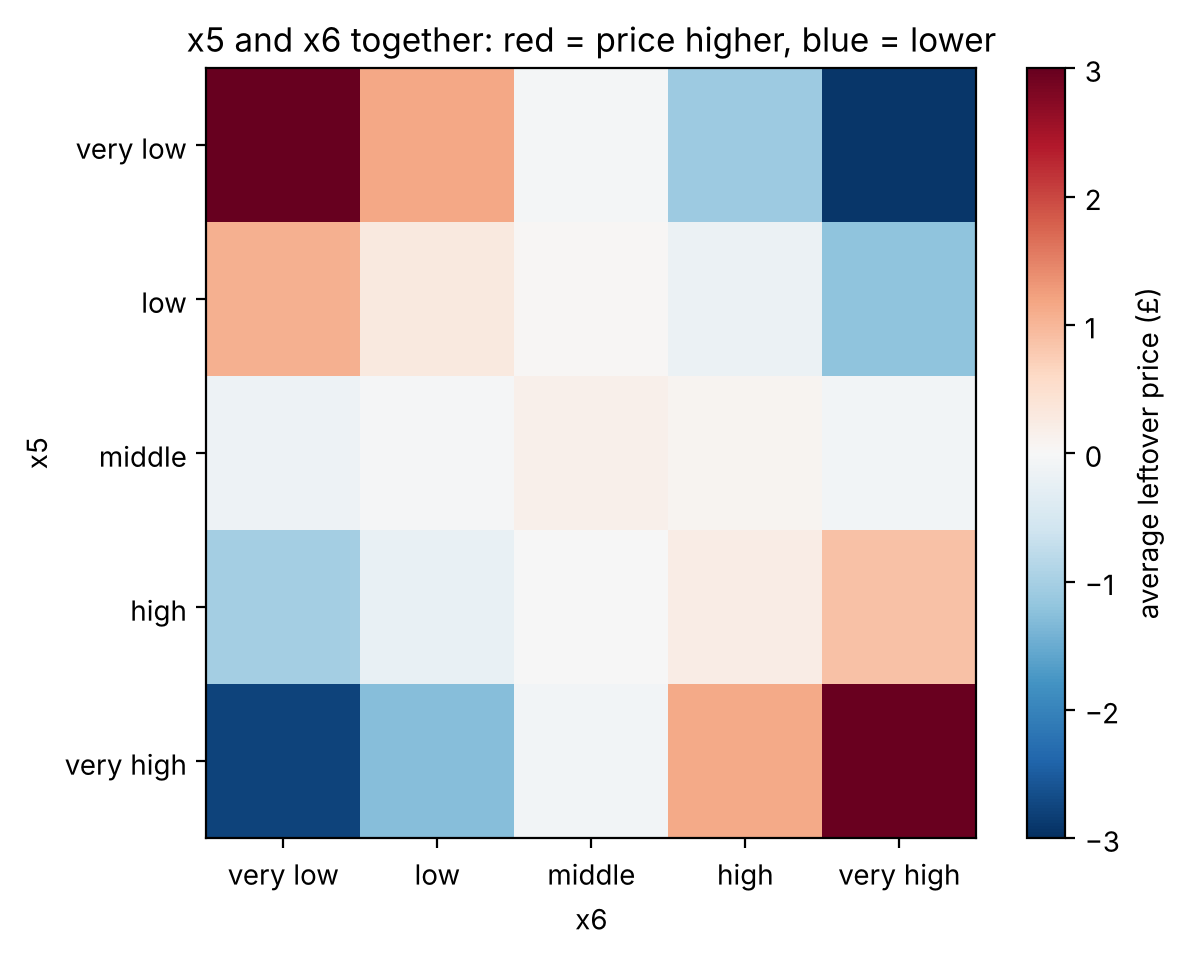

In [10]:
x5_slice = pd.qcut(clean["x5"], 5, labels=["very low", "low", "middle", "high", "very high"])
x6_slice = pd.qcut(clean["x6"], 5, labels=["very low", "low", "middle", "high", "very high"])
grid = leftover.groupby([x5_slice, x6_slice], observed=True).mean().unstack()

plt.figure(figsize=(6.5, 5))
plt.imshow(grid.values, cmap="RdBu_r", vmin=-3, vmax=3)
plt.colorbar(label="average leftover price (£)")
plt.xticks(range(5), grid.columns); plt.yticks(range(5), grid.index)
plt.xlabel("x6"); plt.ylabel("x5")
plt.title("x5 and x6 together: red = price higher, blue = lower")
plt.show()

**How to read the output:** the price is **higher** (red) when x5 and x6 are **both high or both low**, and **lower** (blue) when one is high and the other is low. In the middle row and column, nothing happens.

That's the "two switches" pattern: the effect depends on **x5 × x6**.

**Note:** this is **not** the same as x5 and x6 being correlated with each other (they aren't, Step 3.1). They're independent, but they **act together on the price**.

### Step 3.4: Choose the exact shapes

The V-shape of x2 could be a V (|x2|) or a U (x2²). The S-shape of x3 could be gentle (tanh(x3)) or steep (tanh(2·x3)). `tanh` is simply the maths name for an S-curve that goes from −1 to +1.

**What this cell does:** tries three versions and scores each with 5-fold cross-validation.

In [11]:
def shape_set(data, x2_shape, x3_steepness):
    # the shape clues: x1, x2 as V or U, x3 as an S-curve, x4, and the x5 × x6 team
    return pd.DataFrame({
        "x1": data["x1"],
        "x2_shape": data["x2"].abs() if x2_shape == "V" else data["x2"] ** 2,
        "s_x3": np.tanh(x3_steepness * data["x3"]),
        "x4": data["x4"],
        "x5_times_x6": data["x5"] * data["x6"],
    })

cv = KFold(n_splits=5, shuffle=True, random_state=0)
for x2_shape, k in [("U", 1), ("V", 1), ("V", 2)]:
    rmse = -cross_val_score(LinearRegression(), shape_set(clean, x2_shape, k), clean["price_fixed"], cv=cv,
                            scoring="neg_root_mean_squared_error").mean()
    print(f"x2 as {x2_shape}-shape, x3 as tanh({k}·x3):   CV RMSE £{rmse:.3f}")

x2 as U-shape, x3 as tanh(1·x3):   CV RMSE £4.211
x2 as V-shape, x3 as tanh(1·x3):   CV RMSE £4.166
x2 as V-shape, x3 as tanh(2·x3):   CV RMSE £4.125


**How to read the output:** the **V-shape** beats the U-shape, and the **steeper S-curve**, tanh(2·x3), is best. The differences are small, but they're consistent.

> **✅ Checkpoint.**
> * The clues are **independent of each other**.
> * **x1** goes up, **x4** goes down, **x2** is a V, and **x3** is an S.
> * **x5 and x6 work as a team** (x5 × x6), even though each looks useless alone.
> * **x7 and x8 do nothing.**

---
# Part 4: Test 11 models

### Step 4.1: The fair-test setup and the shape clues

**What this cell does:** sets up the clues (`X`) and the **cleaned** prices (`y`), and turns the shapes from Part 3 into 5 shape clues that a straight-line model can use.

In [12]:
X = clean[clues]
y = clean["price_fixed"]
X_test = test[clues]

def make_shape_clues(data):
    # x1, |x2| (V-shape), tanh(2·x3) (S-shape), x4, and the x5 × x6 team effect
    return shape_set(data, "V", 2)

make_shape_clues(X_test)

,x1,x2_shape,s_x3,x4,x5_times_x6
0,-0.8389,1.1173,0.52932,-1.3617,-0.69779


**How to read the output:** the test row's 5 shape clues. Notice x5 × x6 = −0.70: x5 is high and x6 is low, so the team effect pushes this price **down** a little.

### Step 4.2: The 11 models

We score each model two ways: **CV RMSE** (big misses count extra) and **MAE** (the typical miss). Because of rare price jumps (Part 6), MAE is the better guide to everyday accuracy.

| Family | Model | How it works, in one line |
|---|---|---|
| Straight line | Linear regression | Best straight line through all 8 clues |
| Curves | Polynomial + Ridge | Adds squares, cubes and products of clues, then a line |
| Curves | Splines + Ridge | Bends a flexible ruler along each clue separately (can't see team effects) |
| Distance | KNN | Averages the prices of the most similar rows |
| Trees | Random forest, HistGB, XGBoost, LightGBM | Many decision trees |
| Neural network | MLP | Layers of "neurons" |
| Hand-made | Shape clues + Linear | Our 5 shape clues, then a straight line |
| Hand-made | Shape clues + Huber | The same, but big misses get less say (useful with jumps) |

**What this cell does:** lists each model with the settings to try.

In [13]:
grid_models = {
    "Linear regression": (
        Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]), {}),
    "Polynomial + Ridge": (
        Pipeline([("poly", PolynomialFeatures()), ("scaler", StandardScaler()), ("model", Ridge())]),
        {"poly__degree": [2, 3],                    # squares only, or squares and cubes
         "model__alpha": [1, 100]}),                # how hard the weights are shrunk
    "Splines + Ridge": (
        Pipeline([("spline", SplineTransformer()), ("model", Ridge())]),
        {"spline__n_knots": [5, 10],                # how many bend points along each clue
         "model__alpha": [0.1, 10]}),
    "KNN": (
        Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor())]),
        {"model__n_neighbors": [10, 30, 60]}),      # how many similar rows to average
    "Random forest": (
        Pipeline([("model", RandomForestRegressor(n_estimators=100, max_features=0.5, random_state=0, n_jobs=1))]),
        {"model__min_samples_leaf": [5, 20]}),      # fewest rows at the end of a branch
    "HistGB": (
        Pipeline([("model", HistGradientBoostingRegressor(max_iter=500, random_state=0))]),
        {"model__max_depth": [3, None],             # tree size (None = no limit)
         "model__learning_rate": [0.05, 0.1]}),     # how big a correction each new tree makes
    "Neural network (MLP)": (
        Pipeline([("scaler", StandardScaler()),
                  ("model", MLPRegressor(max_iter=300, early_stopping=True, random_state=0))]),
        {"model__hidden_layer_sizes": [(64, 64), (128, 64)],   # neurons in each layer
         "model__alpha": [0.0001, 0.01]}),                     # penalty that keeps the weights small
    "Shape clues + Linear": (
        Pipeline([("shapes", FunctionTransformer(make_shape_clues)), ("model", LinearRegression())]), {}),
    "Shape clues + Huber": (
        Pipeline([("shapes", FunctionTransformer(make_shape_clues)), ("scaler", StandardScaler()),
                  ("model", HuberRegressor(max_iter=1000))]),
        {"model__epsilon": [1.35, 2.0]}),           # smaller = big misses get less say
}

random_models = {
    "XGBoost": (
        Pipeline([("model", XGBRegressor(random_state=0, n_jobs=1))]),
        {"model__n_estimators": [300, 600, 1000],     # how many trees
         "model__learning_rate": [0.03, 0.05, 0.1],   # how big a correction each new tree makes
         "model__max_depth": [3, 4, 6],               # how big each tree can grow
         "model__min_child_weight": [1, 10],          # fewest rows at the end of a branch
         "model__subsample": [0.8, 1.0],              # share of rows each tree sees
         "model__colsample_bytree": [0.5, 0.8, 1.0],  # share of clues each tree sees
         "model__reg_lambda": [1, 10]}),              # penalty that keeps the effects small
    "LightGBM": (
        Pipeline([("model", LGBMRegressor(random_state=0, n_jobs=1, subsample_freq=1, verbose=-1))]),
        {"model__n_estimators": [300, 600, 1000],
         "model__learning_rate": [0.03, 0.05, 0.1],
         "model__num_leaves": [7, 15, 31],
         "model__min_child_samples": [20, 50],
         "model__subsample": [0.8, 1.0],
         "model__colsample_bytree": [0.5, 0.8, 1.0],
         "model__reg_lambda": [0, 10]}),
}
print("Models ready:", list(grid_models) + list(random_models))

Models ready: ['Linear regression', 'Polynomial + Ridge', 'Splines + Ridge', 'KNN', 'Random forest', 'HistGB', 'Neural network (MLP)', 'Shape clues + Linear', 'Shape clues + Huber', 'XGBoost', 'LightGBM']


### Step 4.3: Run the contest

**What this cell does:** for each model, it
1. tries the settings with 5-fold cross-validation and keeps the best (`GridSearchCV`, or `RandomizedSearchCV` with 10 random combinations for XGBoost and LightGBM)
2. makes fair predictions for every row (`cross_val_predict`) to work out the MAE
3. prices the test row

It takes a few minutes. You'll see "… done" after each model.

In [14]:
results, searches = [], {}

def record(name, search):
    # score one finished search and price the test row
    searches[name] = search
    fair_pred = cross_val_predict(search.best_estimator_, X, y, cv=cv, n_jobs=-1)   # each row predicted by a model that never saw it
    results.append({
        "model": name,
        "CV RMSE (£)": round(-search.best_score_, 3),
        "MAE, typical miss (£)": round(float(np.mean(np.abs(y - fair_pred))), 3),
        "test price (£)": round(float(search.predict(X_test)[0]), 2),
    })
    print(f"{name} done")

for name, (pipe, settings) in grid_models.items():
    search = GridSearchCV(pipe, settings, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

for name, (pipe, settings) in random_models.items():
    search = RandomizedSearchCV(pipe, settings, n_iter=10, cv=cv, random_state=0,
                                scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

results = pd.DataFrame(results).sort_values("MAE, typical miss (£)").reset_index(drop=True)
results

Linear regression done


Polynomial + Ridge done


Splines + Ridge done


KNN done


Random forest done


HistGB done


Neural network (MLP) done
Shape clues + Linear done


Shape clues + Huber done


XGBoost done


LightGBM done


,model,CV RMSE (£),"MAE, typical miss (£)",test price (£)
0,Shape clues + Huber,4.125,2.580,58.64
1,Shape clues + Linear,4.125,2.581,58.62
2,XGBoost,4.177,2.651,58.39
3,Neural network (MLP),4.178,2.656,58.74
4,LightGBM,4.182,2.657,58.59
5,HistGB,4.200,2.674,58.92
6,Polynomial + Ridge,4.267,2.753,56.92
7,Splines + Ridge,4.408,2.896,59.61
8,Random forest,4.457,2.964,59.46
9,KNN,4.604,3.128,57.26


**How to read the output**

* **Shape clues + Linear** and **Shape clues + Huber** are the most accurate (CV RMSE about £4.13, MAE about £2.58). They price the test row at about **£58.6**.
* **XGBoost, the neural network, LightGBM and HistGB** come very close (MAE about £2.65–2.67), and their prices land between about £58.4 and £58.9. They find the shapes, and the team effect, by themselves.
* **Splines** can't see team effects, so they miss x5 × x6. Their price (about £59.6) is about £1 too high.
* **Polynomial**, **random forest**, **KNN** and **linear regression** are less accurate.

### Step 4.4: Accuracy side by side

**What this cell does:** draws MAE and the test price for every model.

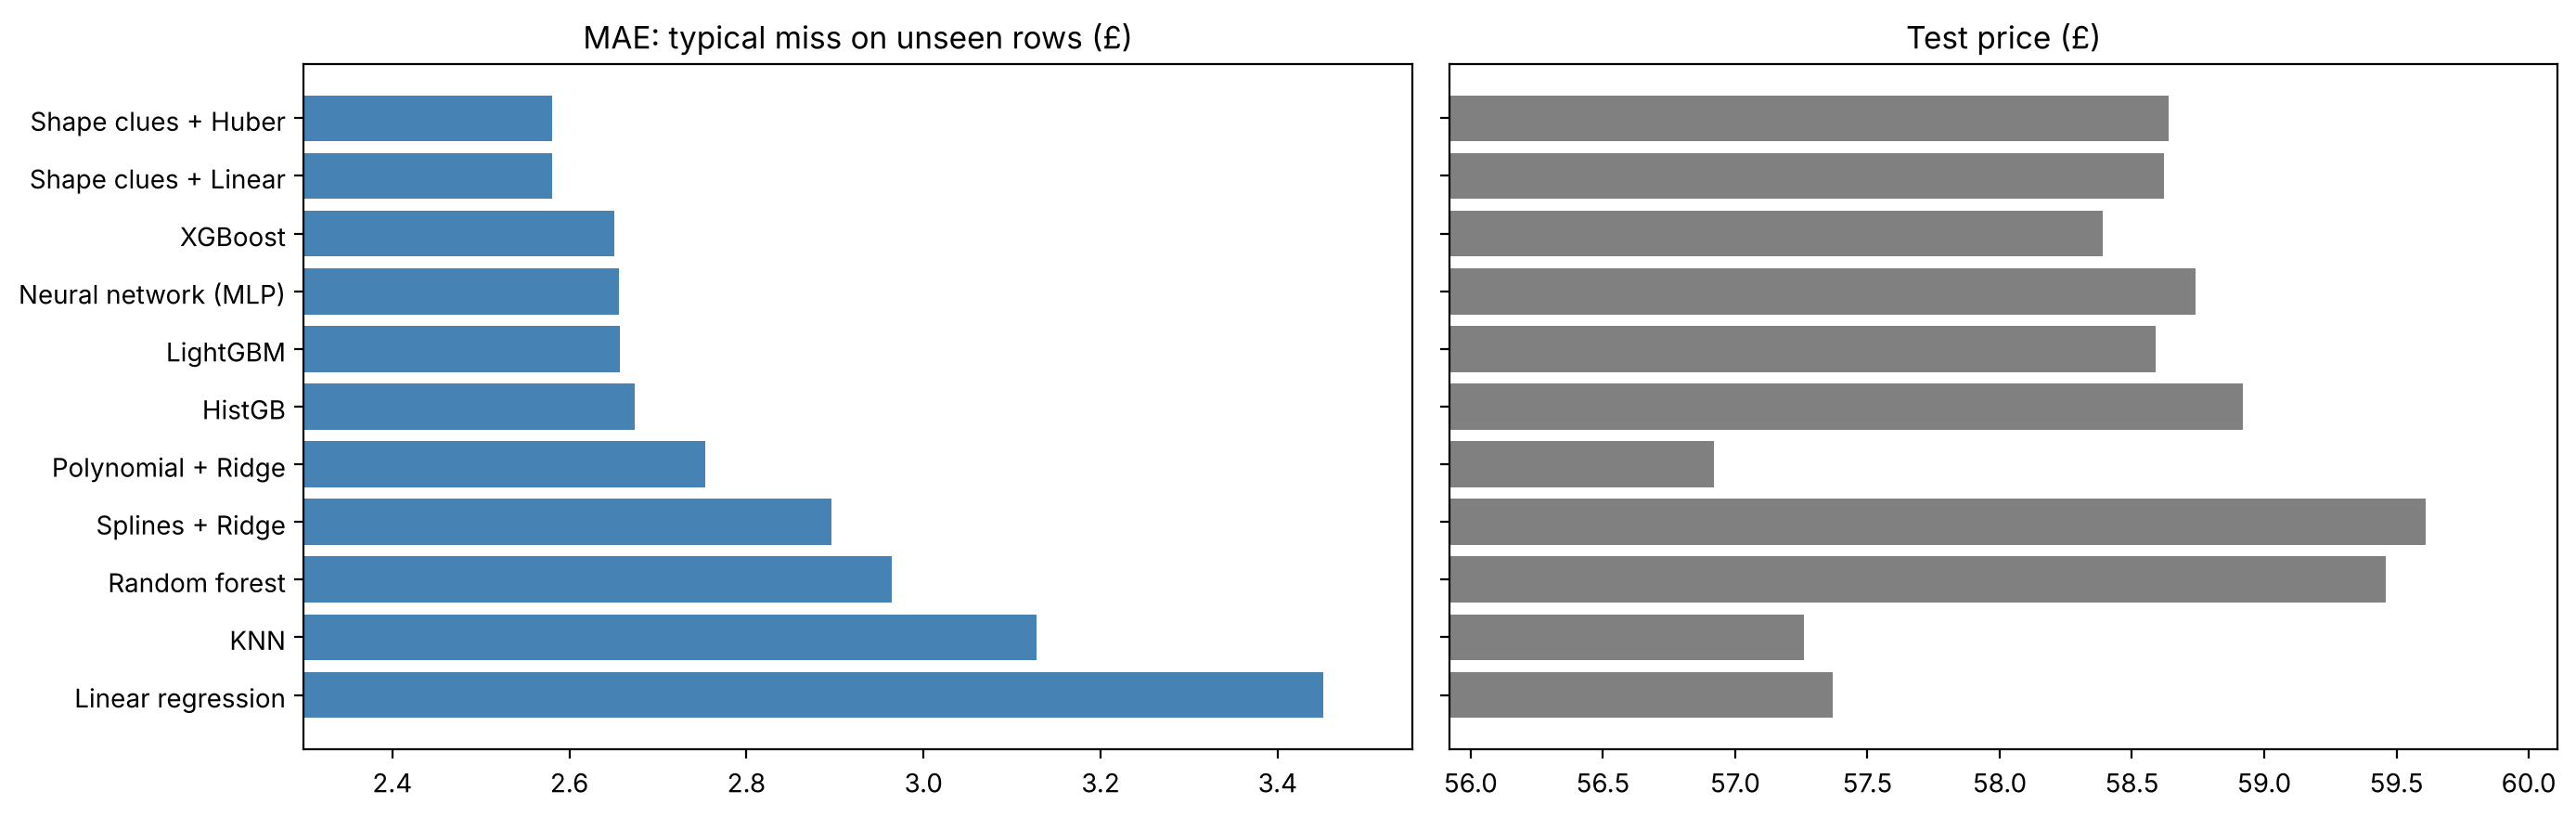

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
axes[0].barh(results["model"], results["MAE, typical miss (£)"], color="steelblue")
axes[0].set_xlim(2.3, results["MAE, typical miss (£)"].max() + 0.1)
axes[0].set_title("MAE: typical miss on unseen rows (£)")
axes[0].invert_yaxis()                                     # best model at the top

axes[1].barh(results["model"], results["test price (£)"], color="grey")
axes[1].set_xlim(results["test price (£)"].min() - 1, results["test price (£)"].max() + 0.5)
axes[1].set_title("Test price (£)")
plt.tight_layout()
plt.show()

### Step 4.5: What if you don't clean the prices?

Many teams won't notice the pence prices. **What this cell does:** trains three models on the **raw** prices (all 30,000 rows, with the 613 pence rows and the 8 junk rows left in), and scores them against the real (cleaned) prices.

In [16]:
raw_X, raw_y = train[clues], train["price"]
real_price = train["price_fixed"].values
scored_rows = ~too_small.values                  # the junk rows can't be scored: we don't know their real price

raw_results = []
for name, model in [("Linear regression", LinearRegression()),
                    ("Shape clues + Linear", Pipeline([("shapes", FunctionTransformer(make_shape_clues)), ("model", LinearRegression())])),
                    ("LightGBM", LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=15, random_state=0, verbose=-1))]:
    fair_pred = cross_val_predict(model, raw_X, raw_y, cv=cv)
    miss = real_price[scored_rows] - fair_pred[scored_rows]
    model.fit(raw_X, raw_y)
    raw_results.append({"model (trained on RAW prices)": name,
                        "MAE vs real prices (£)": round(float(np.mean(np.abs(miss))), 2),
                        "test price (£)": round(float(model.predict(X_test)[0]), 2)})
pd.DataFrame(raw_results)

,model (trained on RAW prices),MAE vs real prices (£),test price (£)
0,Linear regression,115.84,198.50
1,Shape clues + Linear,115.88,189.38
2,LightGBM,129.50,129.84


**How to read the output:** without cleaning, every model is off by **about £115–130** on a typical row, and prices the test row at about **£130–200**, more than **double** the real level of about £58.6. The 2% of pence rows are so big that they drag everything up.

> **✅ Checkpoint.** After cleaning, the good models agree (about £58.4–58.9). Without cleaning, everything is badly wrong. **On this stock the cleaning matters far more than the choice of model.**

---
# Part 5: Pick the most reliable model and look inside it

### Step 5.1: The scorecard

| Model | MAE | Test price | Easy to explain? |
|---|---|---|---|
| **Shape clues + Linear** | **£2.58, the best** | **£58.62** | **Yes: 6 numbers** |
| Shape clues + Huber | £2.58 | £58.64 | Yes |
| XGBoost, neural network, LightGBM, HistGB | £2.65–2.67 | £58.39–58.92 | No |
| Splines (misses x5 × x6) | £2.90 | £59.61 | Partly |
| Any model on raw prices | about £115–130 | £130–200 | — |

**Winner: Shape clues + Linear.** Huber gives the same answer, which confirms the rare jumps aren't pulling the straight line off course.

### Step 5.2: Train the final model and look inside

**What this cell does:** trains the winner on all clean rows, prices the test row, and shows the sum step by step.

In [17]:
final_model = Pipeline([("shapes", FunctionTransformer(make_shape_clues)), ("model", LinearRegression())])
final_model.fit(X, y)
prediction = float(final_model.predict(X_test)[0])

weights = final_model.named_steps["model"].coef_
start = final_model.named_steps["model"].intercept_
test_shapes = make_shape_clues(X_test).iloc[0]

print(f"start{'':30}{start:8.2f}")
total = start
for name, weight in zip(test_shapes.index, weights):
    total += weight * test_shapes[name]
    print(f"+ {weight:6.2f} × {name:12s} ({test_shapes[name]:+6.3f})   {weight * test_shapes[name]:+8.2f}")
print(f"{'= prediction':35}{total:8.2f}")

start                                 55.07
+   5.00 × x1           (-0.839)      -4.19
+   2.95 × x2_shape     (+1.117)      +3.30
+   3.97 × s_x3         (+0.529)      +2.10
+  -2.49 × x4           (-1.362)      +3.39
+   1.49 × x5_times_x6  (-0.698)      -1.04
= prediction                          58.62


**How to read the output**

* **start ≈ £55**: the price when every shape clue is 0.
* **Weights** are about **5** (x1), **3** (|x2|), **4** (S-curve of x3), **−2.5** (x4) and **1.5** (x5 × x6): round numbers again, a good sign we've found the real formula.
* For the test row: x1 takes off about £4, the V of x2 adds about £3, the S of x3 adds about £2, x4 adds about £3, and the team effect takes off about £1.
* **Prediction: £58.62.**

### Step 5.3: See the data and our lines

**What this cell does:** one chart per shape clue. For each one, the effects of the other 4 shape clues are removed from the price, and 3,000 random rows are drawn with our line and the test row's value (dashed).

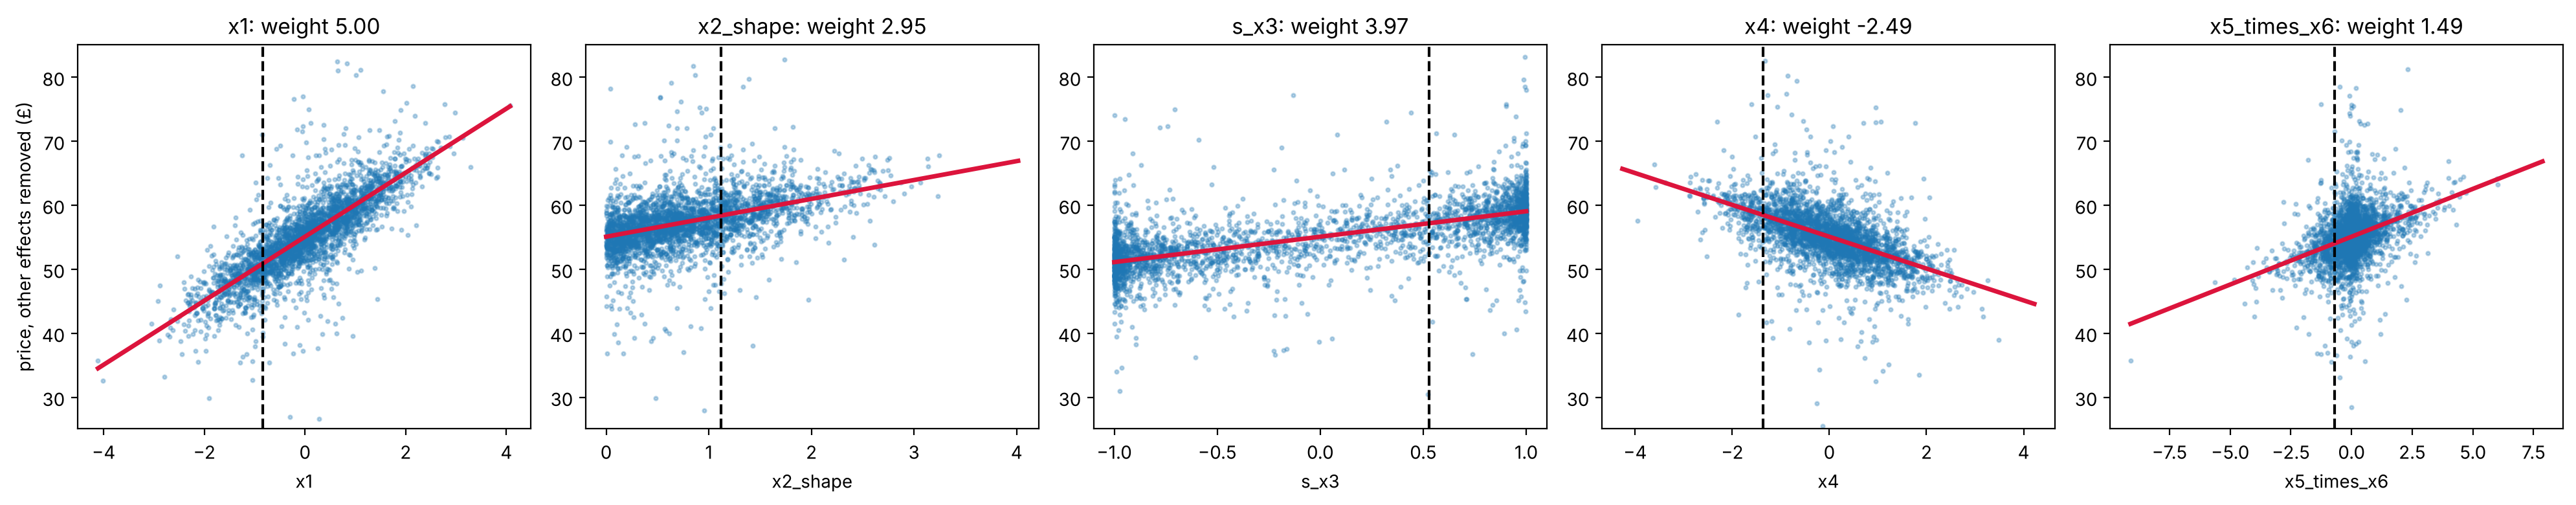

In [18]:
shapes_train = make_shape_clues(X)
sample = shapes_train.sample(3000, random_state=0).index
names = list(shapes_train.columns)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, name, weight in zip(axes, names, weights):
    others = [n for n in names if n != name]
    other_effects = (shapes_train[others] * [weights[names.index(n)] for n in others]).sum(axis=1)
    price_adjusted = y - other_effects                             # price with the other shape effects removed
    ax.scatter(shapes_train.loc[sample, name], price_adjusted[sample], s=4, alpha=0.3)
    xs = np.linspace(shapes_train[name].min(), shapes_train[name].max(), 50)
    ax.plot(xs, start + weight * xs, color="crimson", linewidth=2.5)
    ax.axvline(test_shapes[name], color="black", linestyle="--")
    ax.set_ylim(start - 30, start + 30)
    ax.set_title(f"{name}: weight {weight:.2f}"); ax.set_xlabel(name)
axes[0].set_ylabel("price, other effects removed (£)")
plt.tight_layout()
plt.show()

**How to read the output:** in every chart the dots follow the red line, so once the shapes are turned into shape clues, every effect is a straight line. The few dots far above or below the band are the **jumps** (Part 6). The test row's values (dashed) are all inside the data.

> **✅ Checkpoint.** Final model: **Shape clues + Linear**. Prediction **£58.62**.

---
# Part 6: How sure are we?

### Step 6.1: The leftover is lumpy

**What this cell does:** gets fair predictions for every clean row, then draws the misses (actual − predicted). The second chart uses a **log scale** on the up-axis, so rare big misses become visible.

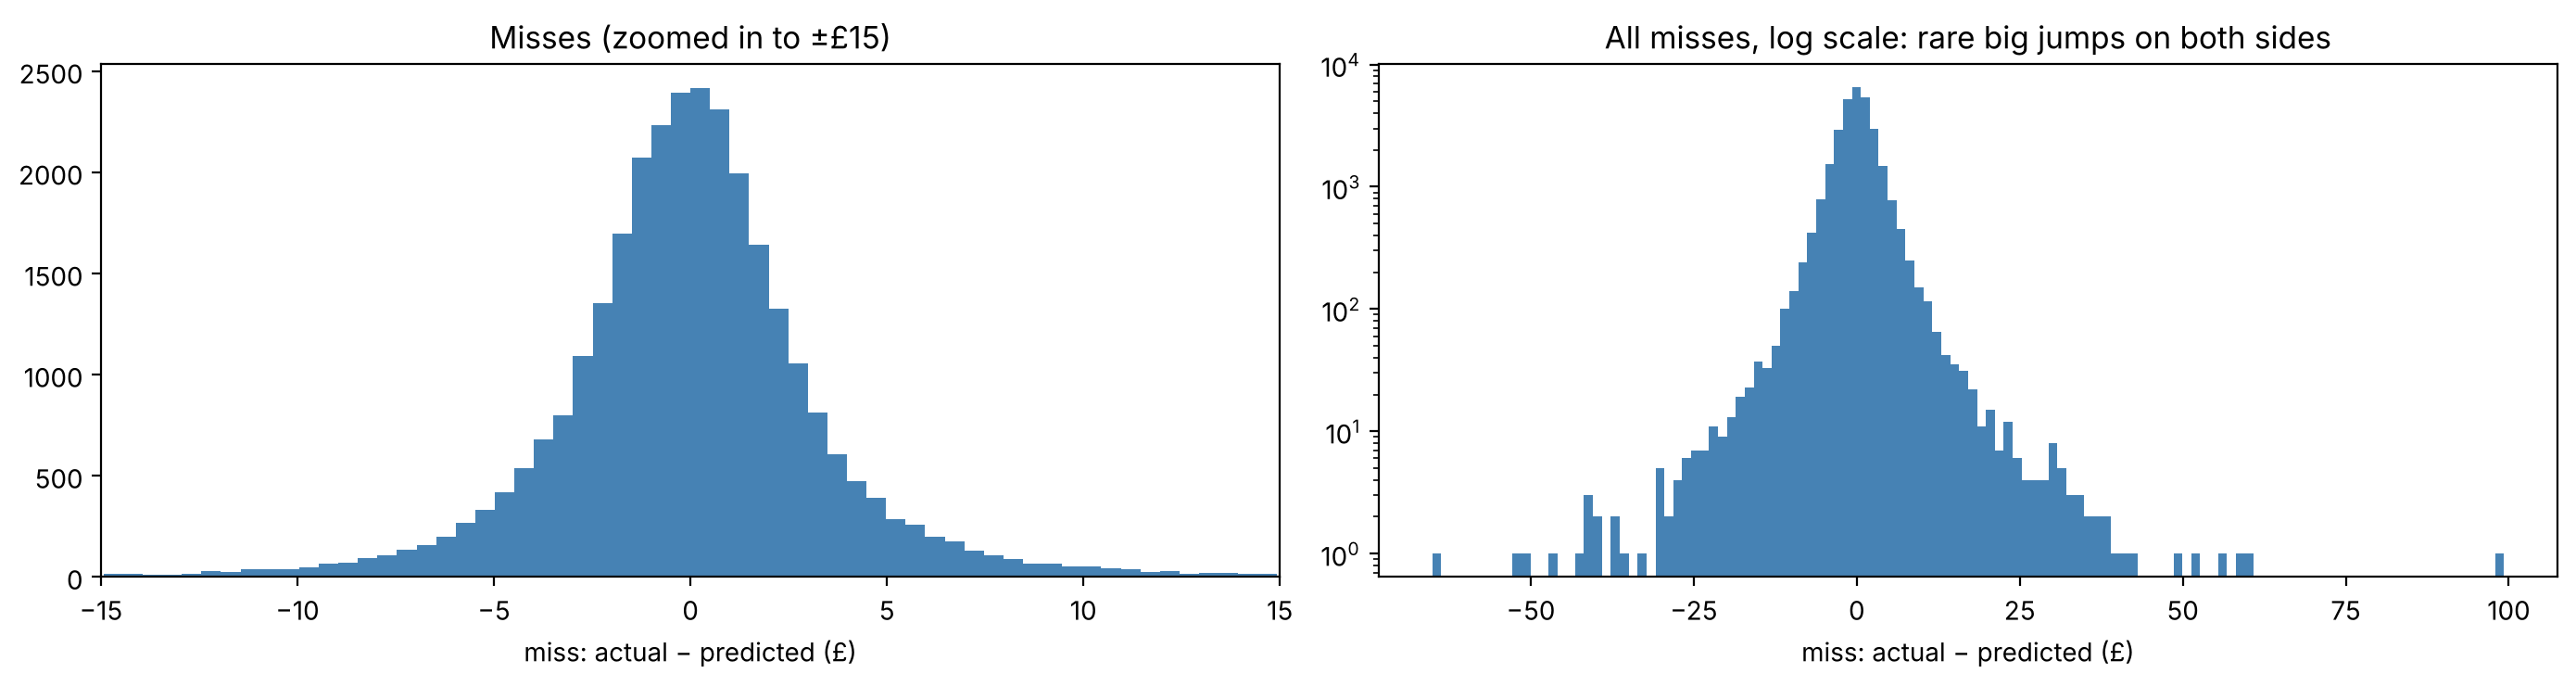

Plain std of the misses:  £4.13
Typical miss (MAE):       £2.58
Misses bigger than £10:   2.7% of rows   (if they were bell-shaped with this std: 1.5%)


In [19]:
fair_pred = cross_val_predict(final_model, X, y, cv=cv)          # each row predicted by a model that never saw it
misses = y - fair_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist(misses[misses.abs() <= 15], bins=60, color="steelblue")
axes[0].set_xlim(-15, 15); axes[0].set_title("Misses (zoomed in to ±£15)")
axes[1].hist(misses, bins=120, color="steelblue", log=True)
axes[1].set_title("All misses, log scale: rare big jumps on both sides")
for ax in axes:
    ax.set_xlabel("miss: actual − predicted (£)")
plt.tight_layout()
plt.show()

print(f"Plain std of the misses:  £{misses.std():.2f}")
print(f"Typical miss (MAE):       £{misses.abs().mean():.2f}")
bell_share = erfc(10 / (misses.std() * np.sqrt(2)))           # share beyond £10 if the misses were bell-shaped
print(f"Misses bigger than £10:   {(misses.abs() > 10).mean():.1%} of rows   (if they were bell-shaped with this std: {bell_share:.1%})")

**How to read the output**

* Most misses are small: a narrow bell of about ±£3.
* But a small share of rows have **jumps** of £10–30, up or down, and a handful even more (the most extreme are 2–3 times, or a fifth of, the expected price). The log-scale chart shows these long "tails" on both sides.
* Misses bigger than £10 happen about **2.7%** of the time. If the misses were bell-shaped with the same std, that would be about 1.5%.

The jumps are random: no clue predicts them. Nobody can know whether the test row will have one.

**Why this matters:** the plain std (£4.12) is a **bad ruler** here. It's too big for normal rows (68% of misses are within about ±£2.70) and too small for the jumps. So instead of std, we use the **actual share of misses** inside each range.

### Step 6.2: The ranges, from real misses

**What this cell does:** finds the half-width that contains 68%, 95% and 99.7% of the misses. These match "1 std", "2 std" and "3 std" for a bell shape, but they're measured from the real data.

In [20]:
band = {share: float(np.percentile(misses.abs(), share)) for share in [68, 95, 99.7]}
for share, h in band.items():
    print(f"{share:>5}% of misses are within ±£{h:.2f}")

jump_up = (misses > 15).mean()
print(f"\nChance the true price is more than £15 ABOVE the prediction: {jump_up:.2%}  (about 1 in {1 / jump_up:.0f})")

   68% of misses are within ±£2.69
   95% of misses are within ±£7.60
 99.7% of misses are within ±£23.94

Chance the true price is more than £15 ABOVE the prediction: 0.54%  (about 1 in 184)


**How to read the output:** 68% of rows are within about **±£2.70**, 95% within about **±£7.60**, and 99.7% within about **±£24**. The last range is far wider than "3 × £2.70" because of the jumps. A jump of more than £15 **upwards** happens about **1 time in 180**.

### Step 6.3: Model error (bootstrap)

**What this cell does:** retrains the final model 200 times on random rows (some twice, some not at all) and prices the test row each time.

In [21]:
rng = np.random.default_rng(0)
boot_prices = []
for b in range(200):
    rows_b = rng.integers(0, len(clean), len(clean))
    model_b = clone(final_model).fit(X.iloc[rows_b], y.iloc[rows_b])
    boot_prices.append(float(model_b.predict(X_test)[0]))
boot_prices = np.array(boot_prices)
print(f"Average test price over 200 retrains: £{boot_prices.mean():.2f}    spread (std): £{boot_prices.std():.2f}")

Average test price over 200 retrains: £58.62    spread (std): £0.05


**How to read the output:** the model itself moves by only about **5p**. Almost all our uncertainty is the price's own randomness (Step 6.2).

> **✅ Checkpoint.** Price **£58.62**. About 68% chance within ±£2.70, 95% within ±£7.60, and 99.7% within about ±£24 (because of the rare jumps).

---
# Part 7: Make a quote and a trading plan

### Step 7.1: Quote options

**What this cell does:** prints quotes (**bid = centre − h**, **ask = centre + h**) for the three ranges from Step 6.2.

In [22]:
centre = prediction
for share, label in [(68, "like 1 std"), (95, "like 2 std"), (99.7, "like 3 std")]:
    h = band[share]
    print(f"{label}:  bid £{centre - h:.2f}   ask £{centre + h:.2f}   (true price inside about {share}% of the time)")

like 1 std:  bid £55.93   ask £61.31   (true price inside about 68% of the time)
like 2 std:  bid £51.02   ask £66.22   (true price inside about 95% of the time)
like 3 std:  bid £34.68   ask £82.56   (true price inside about 99.7% of the time)


### Step 7.2: Should we try to be market maker?

**What the other teams will probably do:**
* **Teams that didn't clean the prices** think the price is about **£130–200**, with a CV RMSE above £100. They'll quote very wide, so they **won't** become market maker. But they'll **buy as much as they can** from whoever is market maker, because every normal ask looks cheap to them.
* **Teams that cleaned** will price it at about **£58.4–59.6**, and some of them will compete for the seat.

**So the money on this stock is in being market maker:** the teams that didn't clean will buy from us, and on average each share they buy is worth less than they pay.

**The risk is the jumps.** If the true price happens to jump up (about a 1-in-180 chance of more than £15, Step 6.2), we lose on every share we sold. A wider quote earns more per share and protects us better:

| Quote | Earned per share (on average) | If the price jumps £15 above our centre |
|---|---|---|
| ±£2.70 | about £2.70 | lose about £12.30 per share |
| ±£7.60 | about £7.60 | lose about £7.40 per share |

**Suggestion:** quote the **95% range (about £51.0 / £66.2)**. It's tight enough to have a chance at market maker against teams quoting ±2 × their £4 RMSE, and safe enough if a jump comes. If you want to stay out of the seat, use the 99.7% range.

### Step 7.3: Trading plan (if another team is market maker)

Compare their bid and ask with our centre (**£58.62**), using the ranges from Step 6.2:

| Market maker's prices | What we do | Size |
|---|---|---|
| **Bid above about £82.6** (beyond the 99.7% range) | **Sell** | **Maximum** |
| Bid between about £66.2 and £82.6 | Sell | Big |
| Bid between about £61.3 and £66.2 | Sell | Small to medium |
| **Ask below about £34.7** (beyond the 99.7% range) | **Buy** | **Maximum** |
| Ask between about £34.7 and £51.0 | Buy | Big |
| Ask between about £51.0 and £55.9 | Buy | Small to medium |
| Our centre within about £2.70 of their prices | Little edge | Minimum 10 shares, on the side our centre leans towards |

**Likely scenarios:**
* Market maker **didn't clean the prices** (mid about £130–200) → **sell the maximum**: about £70–140 of edge per share.
* Market maker cleaned but used **splines** (about £59.6) → little edge.
* Market maker cleaned and used **any good model** (about £58.4–58.9) → no edge, trade the minimum.

---

### Lessons so far

| Stock | Trap | What we did |
|---|---|---|
| 1 | None (warm-up) | Linear regression, quote ±1–2 std |
| 2 | Few rows, extreme test row | Wide quote (±£15), stay a trader |
| 3 | Out-of-range **decoy** clue | Checked it has no effect, removed it, confident quote |
| 4 | **Missing near-copy of the price** (x7), **noise that depends on x5** | Dropped x7, measured the noise where the test row lives |
| 5 | **Missing value + rare sector** | Flag for missing x3, a separate x1 weight per sector |
| 7 | **Prices in pence + junk prices**, a **team effect**, **jumpy noise** | Cleaned the prices, found x5 × x6, used real miss ranges instead of std |

> **✅ Final checkpoint.** Stock 7 price **£58.62**. Most reliable model: **Shape clues + Linear**. The clues are independent of each other, but x5 and x6 act as a team. The biggest danger is forgetting to clean the prices.